**Name: Poojitha Kore**

**Tutor: Mohamad Hoseini**

# Fairness in Machine Learning: Evaluating and Mitigating Bias in Adult Census Income Prediction

## 1. Introduction

### 1.1 Business Problem

Machine learning is increasingly used to support business decisions by identifying patterns in data and predicting outcomes. However, a model can achieve good overall predictive performance while producing different outcomes or error rates for different demographic groups. If these disparities are overlooked, an organisation may make decisions that disadvantage certain groups, potentially reducing trust, transparency, and the responsible use of artificial intelligence.

This project investigates algorithmic fairness using the Adult Census Income dataset. The task is to predict whether an individual's recorded annual income exceeds $50,000. Although this is a classification problem, the project focuses not only on predictive performance but also on whether the model's predictions and errors differ across sex and race groups.

In a real organisational setting, relevant data would need to be collected from reliable and governed sources, with clearly defined target outcomes and documented demographic attributes where legally and ethically appropriate. Data collection should include appropriate privacy, access-control and governance measures because sensitive attributes may be required for fairness auditing even when they are excluded from model prediction. The quality and representativeness of the collected data would also need to be monitored to reduce the risk of historical or sampling bias.

### 1.2 Business Importance and Organisational Benefit

For an organisation considering income-related predictive analytics, understanding these differences can help identify risks before a model is used to support business decisions. Evaluating fairness alongside accuracy can help the organisation assess model reliability, identify potentially disadvantaged groups, improve accountability, and make more informed decisions about whether a model is suitable for its intended purpose.

The business objective is therefore not simply to maximise prediction accuracy. It is to investigate whether the model can provide useful predictions while reducing unjustified differences in outcomes across demographic groups. Any proposed improvement must be evaluated using both predictive-performance and fairness measures.

The dataset is used for an educational fairness assessment. Its results should not be interpreted as evidence that income predictions are appropriate for making individual decisions about employment, credit, or access to services.

### 1.3 Data Source and Machine Learning Formulation

The project uses the publicly available Adult Census Income dataset, which contains demographic, employment-related, and other socioeconomic attributes alongside an income category. The dataset is sourced from a public dataset repository rather than collected directly from a company or individuals for this project.

The problem is formulated as a supervised binary classification task:

- **Input features:** selected demographic and socioeconomic variables, excluding the target and the sensitive attributes used for group evaluation.
- **Target variable:** recorded income category.
- **Negative class (0):** income of `<=50K`.
- **Positive class (1):** income of `>50K`.
- **Baseline model:** Logistic Regression.
- **Sensitive attributes for fairness evaluation:** sex and race.

The baseline model is evaluated using a held-out test set. Its predictive performance is assessed using accuracy, precision, recall, and F1-score. Fairness is investigated by comparing group-level prediction outcomes and error rates, including false-positive and false-negative rates.

### 1.4 Project Objective

The project has two connected objectives. First, it evaluates the baseline classifier to identify potential disparities in predictions and errors across sex and race groups. Second, it investigates a suitable fairness-mitigation approach and compares the resulting model with the baseline.

The analysis will consider whether the selected intervention reduces the measured disparities while maintaining useful predictive performance. The findings will be used to discuss the method's strengths, limitations, ethical implications, and suitability for responsible business use.


## 2. Aim, Objectives and Research Questions
### 2.1 Aim

The aim of this project is to evaluate potential algorithmic unfairness in a Logistic Regression classifier trained on the Adult Census Income dataset and investigate whether fairness mitigation can reduce measured disparities while maintaining useful predictive performance.

### 2.2 Objectives

1. Develop and evaluate a baseline Logistic Regression classifier for predicting income categories.
2. Examine differences in prediction outcomes and classification errors across sex and race groups.
3. Evaluate selection rates, true-positive rates (TPR), false-positive rates (FPR), false-negative rates (FNR), the Disparate Impact Ratio (DIR) for sex, and Equalized Odds Difference across sex and race groups.
4. Apply Fairlearn's ExponentiatedGradient method with an EqualizedOdds constraint, separately using sex and race as the sensitive attribute during mitigation.
5. Compare the baseline and mitigated models on the same held-out test set, considering predictive performance and fairness measures.
6. Discuss the effectiveness, limitations, ethical implications, and potential business consequences of the resulting pipeline.

### 2.3 Research Questions

1. How effectively does the baseline Logistic Regression model predict the two income categories?
2. Do prediction outcomes and classification error rates differ across sex and race groups?
3. What do the selected fairness measures reveal about potential group disparities?
4. How do the models mitigated using sex or race compare with the baseline model?
5. Does either mitigation approach reduce measured disparities, and what trade-offs occur in predictive performance or the other audited attribute?
6. What recommendations can be made for responsible evaluation and use of this machine-learning pipeline?

### 2.4 Fairness Concepts

- **Predictive equality:** examines whether false-positive rates are similar across groups.
- **Equal opportunity:** examines whether true-positive rates are similar across groups.
- **Disparate impact:** compares favourable prediction rates across demographic groups. In this project, the Disparate Impact Ratio (DIR) is calculated by dividing the female selection rate by the male selection rate. It is used to compare selection-rate differences across the baseline and mitigated models. DIR complements Equalized Odds analysis but does not, by itself, establish fairness or discrimination.
- **Disparate mistreatment:** examines whether classification errors differ across groups.

These measures assess different aspects of fairness. No single metric establishes that a model is fair overall (Fairlearn, n.d.-a).



## 3. Dataset and Variables
### 3.1 Dataset Description and Source

This project uses the Adult Census Income dataset, originally documented by Becker and Kohavi (1996) and available through the UCI Machine Learning Repository. The CSV file analysed in this project was obtained from the Adult Census Income dataset distributed on Kaggle.

The dataset contains 32,561 observations and 15 columns, comprising 14 predictor attributes and the income target. A comparison with UCI's `adult.data` training file confirmed that the records match after normalising whitespace and missing-value representations, although their row order differs.

The complete UCI collection includes 48,842 records across `adult.data` and `adult.test`. This project analyses the 32,561-record training portion rather than the complete collection. Therefore, the results apply to the selected dataset version, preprocessing steps, train-test split and evaluation settings used in this notebook.

The dataset reflects historical socioeconomic conditions and is observational in nature. Associations between demographic or employment-related attributes and income do not establish causation. Its limitations and unequal demographic representation should be considered when interpreting predictive performance and fairness outcomes.

**Data source:** [Adult Census Income — Kaggle](https://www.kaggle.com/datasets/uciml/adult-census-income)

**Original dataset:** [UCI Machine Learning Repository — Adult](https://doi.org/10.24432/C5XW20)

### 3.2 Target Variable and Classification Task

The target variable is `income`, which is represented as a binary outcome:

- **Class 0 — Unfavourable outcome:** recorded income `<=50K`.
- **Class 1 — Favourable outcome:** recorded income `>50K`.

The task is to train a Logistic Regression classifier to predict the recorded income category from the selected input features. The term *favourable outcome* is used for the purpose of the fairness analysis; it does not imply that income alone determines a person's ability, value, or suitability for a decision.

### 3.3 Input and Sensitive Attributes

The baseline model uses selected demographic and socioeconomic features available in the dataset. The target variable is excluded from the input features to avoid using the answer as a predictor.

The attributes `sex` and `race` are retained separately as **sensitive attributes for group-level fairness evaluation** and are excluded from the baseline model's input features. This allows the analysis to compare prediction outcomes and errors across groups.

Excluding sensitive attributes from the model inputs does not guarantee fairness. Other input variables may be associated with sex or race and can indirectly reflect demographic differences.

### 3.4 Data Preparation

Before model training, the dataset is checked and prepared for analysis. Unknown values represented by `?` are converted to missing values, and the income labels are standardised into the two target classes.

The dataset is divided into training and test sets using an 80:20 split, with stratification by the target class and a fixed random seed of 42. Numerical and categorical features are processed separately. The preprocessing pipeline is fitted on the training data and then applied to the test data to reduce the risk of data leakage.

The test set is kept separate from model fitting and is used to evaluate predictive performance and group-level fairness. The same test set should be used for the baseline and mitigation comparison so that their results can be compared consistently.

## 4. Imports, Setup and Dataset loading




In [198]:
# Install Fairlearn
%pip -q install fairlearn

# Standard libraries
import numpy as np
import pandas as pd
import math
from pathlib import Path
import pandas as p

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# Fairlearn
from fairlearn.reductions import ExponentiatedGradient, EqualizedOdds
from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    true_positive_rate,
    false_positive_rate,
    equalized_odds_difference
)


print("All imports completed successfully.")


All imports completed successfully.


Load and inspect the dataset:

In [199]:
# Preferred location for a portable GitHub project
DATA_PATH = Path("data") / "adult.csv.zip"

# Fallbacks for local Jupyter and your existing Google Colab setup
if not DATA_PATH.exists():
    if Path("adult.csv.zip").exists():
        DATA_PATH = Path("adult.csv.zip")
    elif Path("/content/adult.csv.zip").exists():
        DATA_PATH = Path("/content/adult.csv.zip")
    else:
        raise FileNotFoundError(
            "Dataset not found. Please place adult.csv.zip inside "
            "the project's data folder, or in the notebook's working "
            "directory. In Google Colab, you can also place it at "
            "/content/adult.csv.zip."
        )

print(f"Loading dataset from: {DATA_PATH.resolve()}")
df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully: {df.shape[0]} rows, {df.shape[1]} columns")


Loading dataset from: /content/adult.csv.zip
Dataset loaded successfully: 32561 rows, 15 columns


In [200]:
print(df.shape)
display(df.head())

(32561, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


### 4.1 Data Cleaning and Preparation

#### Missing and Unknown Values

In [201]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

In [202]:
# Remove extra spaces from text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

In [203]:
# Replace '?' with missing values
df.replace("?", np.nan, inplace=True)

In [204]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64


The missing-value analysis indicates that the dataset contains incomplete observations in three features: workclass, occupation, and native.country. The occupation column has the highest number of missing values (1,843), followed closely by workclass (1,836), while native.country contains 583 missing values. The remaining 12 columns, including the target variable income and the sensitive attributes sex and race, have no missing values.

In [205]:
# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 24


The dataset contains 24 duplicate rows, which were removed during data cleaning to avoid redundant observations and improve data quality.

In [206]:
df = df.drop_duplicates().copy()
print("Duplicate rows after cleaning:", df.duplicated().sum())


Duplicate rows after cleaning: 0


After removing the 24 duplicate rows, no duplicate records remain in the dataset.

In [207]:
print("Dataset shape after cleaning:",df.shape)

Dataset shape after cleaning: (32537, 15)


The cleaned dataset contains 32,537 rows and 15 columns, ensuring that each remaining record is unique.

### 4.2 Final Dataset validation

In [208]:
print("\nData types:")
print(df.dtypes)


Data types:
age                int64
workclass         object
fnlwgt             int64
education         object
education.num      int64
marital.status    object
occupation        object
relationship      object
race              object
sex               object
capital.gain       int64
capital.loss       int64
hours.per.week     int64
native.country    object
income            object
dtype: object


The dataset contains both numerical (int64) and categorical (object) variables. Six features are numerical, including age, education.num, and hours.per.week, while nine are categorical, including workclass, sex, race, and income.

This distinction guides preprocessing: numerical features require numerical imputation and scaling, while categorical features require categorical imputation and one-hot encoding.

In [209]:
print("\nNumerical summary:")
display(df.describe().round(2))


Numerical summary:


,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32537.00,32537.00,32537.00,32537.00,32537.00,32537.00
mean,38.59,189780.85,10.08,1078.44,87.37,40.44
std,13.64,105556.47,2.57,7387.96,403.10,12.35
min,17.00,12285.00,1.00,0.00,0.00,1.00
25%,28.00,117827.00,9.00,0.00,0.00,40.00
50%,37.00,178356.00,10.00,0.00,0.00,40.00
75%,48.00,236993.00,12.00,0.00,0.00,45.00
max,90.00,1484705.00,16.00,99999.00,4356.00,99.00


The dataset represents individuals with a mean age of 38.59 years and average working hours of 40.44 hours per week. Both capital.gain and capital.loss have median values of zero, indicating that at least half of the observations report no recorded capital gains or losses.

The numerical distributions are skewed, particularly capital gains, capital losses and fnlwgt. These distributions are retained because the modelling pipeline applies scaling to numerical predictors, while the analysis recognises that extreme values may still influence the linear model.

In [210]:
print("\nCategorical summary:")
display(df.describe(include="object"))


Categorical summary:


,workclass,education,marital.status,occupation,relationship,race,sex,native.country,income
count,30701,32537,32537,30694,32537,32537,32537,31955,32537
unique,8,16,7,14,6,5,2,41,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,22673,10494,14970,4136,13187,27795,21775,29153,24698


The categorical summary shows that Private is the most common workclass, HS-grad is the most frequent education level, and United-States is the predominant native country. The target variable is imbalanced: 24,698 individuals (approximately 75.9%) earn <=50K, compared with 7,839 (approximately 24.1%) earning >50K.

The dataset is also demographically concentrated, with 27,795 observations identifying as White and 21,775 as Male. These distributions are important when interpreting model performance and evaluating fairness across demographic groups.

### 4.3 Final Target and Sensitive-Attribute Validation

In [211]:
# Check required columns
required_columns = ["income", "sex", "race"]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Required column '{col}' is missing.")

# Check target and sensitive attribute values
print("Income values:")
print(df["income"].value_counts(dropna=False))

print("\nSex values:")
print(df["sex"].value_counts(dropna=False))

print("\nRace values:")
print(df["race"].value_counts(dropna=False))

Income values:
income
<=50K    24698
>50K      7839
Name: count, dtype: int64

Sex values:
sex
Male      21775
Female    10762
Name: count, dtype: int64

Race values:
race
White                 27795
Black                  3122
Asian-Pac-Islander     1038
Amer-Indian-Eskimo      311
Other                   271
Name: count, dtype: int64


The target distribution is imbalanced: approximately 75.9% of individuals earn <=50K, while 24.1% earn >50K. The dataset also contains more males (21,775) than females (10,762), and White individuals form the largest racial group (27,795).

These demographic imbalances are important when evaluating model performance and fairness, as overall metrics may conceal differences in prediction errors across income, sex, and racial groups.

In [212]:
# Standardise the target labels
df["income"] = (
    df["income"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.$", "", regex=True)
)

# Remove rows without a target or sensitive-group label
df = df.dropna(subset=["income", "sex", "race"]).copy()

# Encode income: 0 = <=50K, 1 = >50K
income_mapping = {
    "<=50K": 0,
    ">50K": 1
}

y = df["income"].map(income_mapping)

# Check for unexpected target labels
if y.isna().any():
    unexpected = df.loc[y.isna(), "income"].unique()
    raise ValueError(f"Unexpected income labels: {unexpected}")

y = y.astype(int)

# Keep sensitive attributes for auditing, not as model inputs
sensitive_features = df[["sex", "race"]].copy()

X = df.drop(columns=["income", "sex", "race"]).copy()

# Verify alignment and dimensions
assert X.index.equals(y.index)
assert X.index.equals(sensitive_features.index)

print("Feature matrix shape:", X.shape)
print("\nTarget distribution:")
display(y.value_counts().sort_index())

print("\nSensitive attributes:")
display(sensitive_features.nunique())


Feature matrix shape: (32537, 12)

Target distribution:


,count
income,
0,24698
1,7839



Sensitive attributes:


,0
sex,2
race,5


The original dataset contains six numerical columns and nine categorical columns, including the target variable and sensitive attributes. For modelling, the income target and the sensitive attributes sex and race are excluded from the predictor matrix. The resulting feature matrix contains 12 predictors: six numerical and six categorical features. Numerical predictors are imputed using the median and scaled, while categorical predictors are imputed using the most frequent value and one-hot encoded.

## 5. Exploratory Data Analysis

### 5.1 Target variable distribution

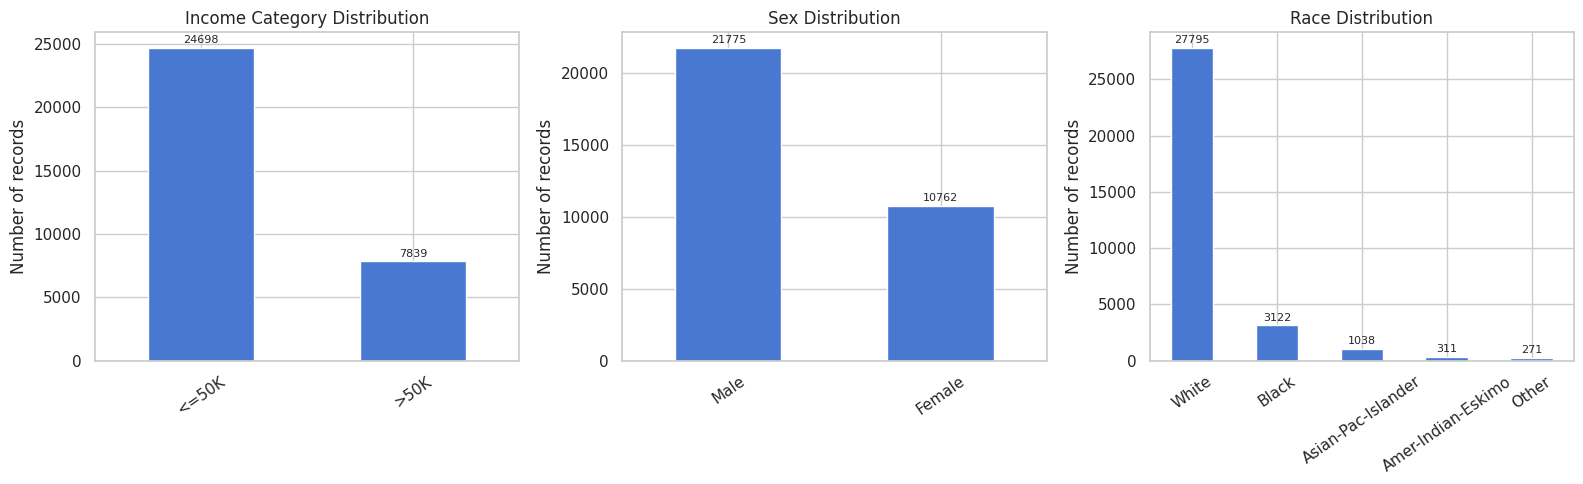

In [213]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

plot_columns = ["income", "sex", "race"]
titles = [
    "Income Category Distribution",
    "Sex Distribution",
    "Race Distribution"
]

for ax, column, title in zip(axes, plot_columns, titles):
    counts = df[column].value_counts()

    counts.plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Number of records")
    ax.tick_params(axis="x", rotation=35)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=2, fontsize=8)

plt.tight_layout()
plt.show()


**Visualization 1: Income Distribution**

The income distribution shows that 24,698 individuals (75.9%) earn <=50K, while 7,839 (24.1%) earn >50K, indicating a clear class imbalance. The sex distribution includes 21,775 males (66.9%) and 10,762 females (33.1%). For race, White individuals account for 27,795 records (85.4%), followed by Black individuals with 3,122 (9.6%), Asian-Pac-Islander with 1,038 (3.2%), Amer-Indian-Eskimo with 311 (1.0%), and Other with 271 (0.8%). These uneven group sizes may affect the reliability of subgroup performance and fairness metrics, particularly for smaller racial groups.

**Visualization 2 & 3: Sex and Race Distribution**

The dataset contains 21,775 male observations (66.9%) and 10,762 female observations (33.1%). White individuals represent 27,795 observations (85.4%), followed by Black individuals (9.6%), Asian-Pac-Islander individuals (3.2%), Amer-Indian-Eskimo individuals (1.0%), and individuals classified as Other (0.8%).

These distributions show that the demographic groups are unevenly represented, particularly across racial categories. Smaller groups may produce less stable fairness estimates, so sample sizes should be considered when interpreting group-level results. Unequal representation alone does not establish that a model is biased; differences in prediction outcomes and error rates must also be evaluated.

### 5.2 Numerical feature analysis

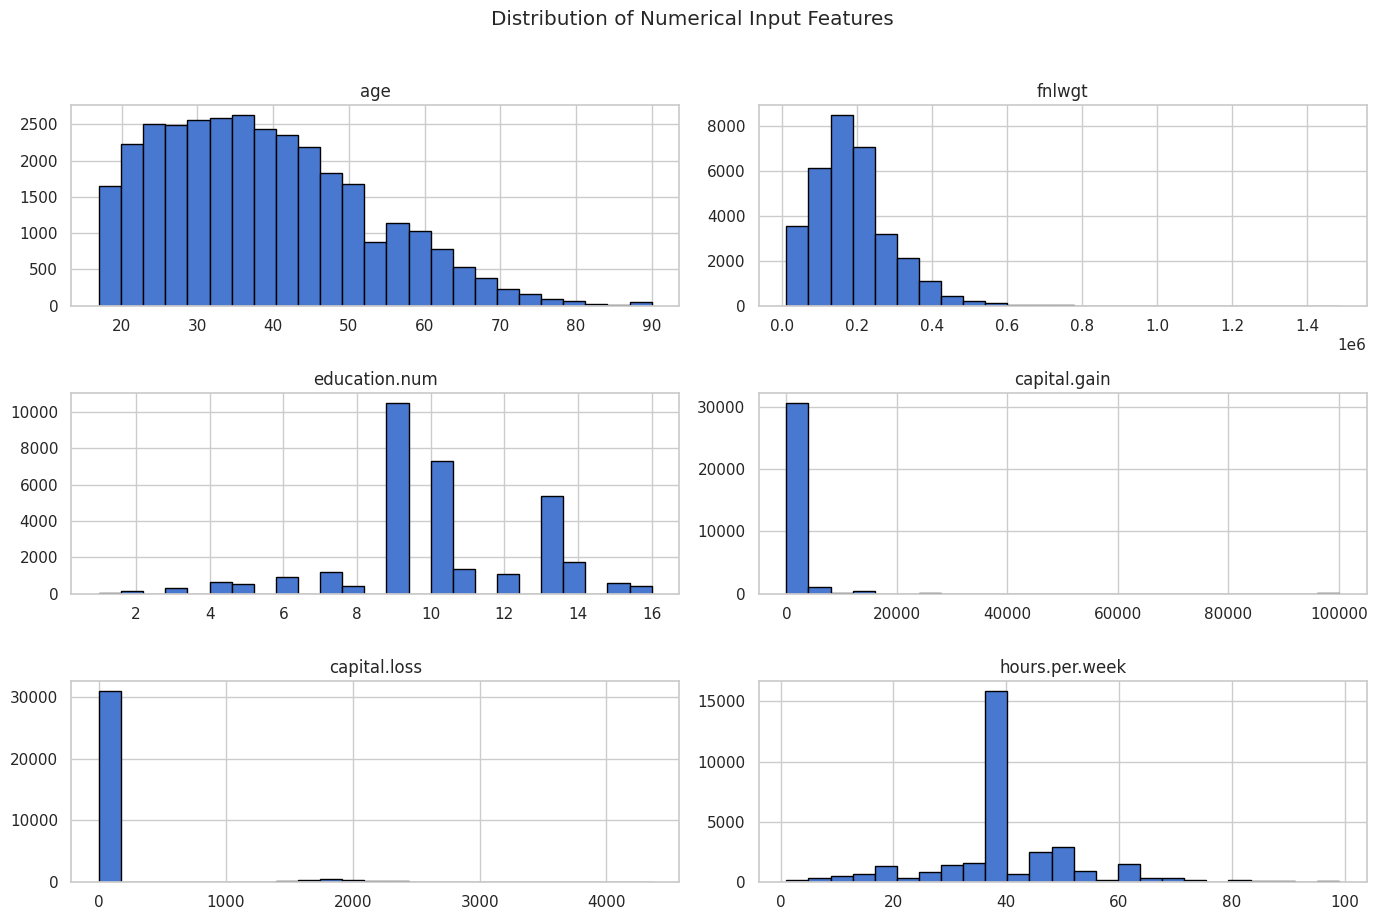

In [214]:
numeric_cols = X.select_dtypes(include="number").columns.tolist()

X[numeric_cols].hist(
    figsize=(14, 9),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Input Features", y=1.02)
plt.tight_layout()
plt.show()


**Distribution of Numerical Features**

The distributions of the numerical features reveal substantial variation in the characteristics of individuals represented in the Adult Census Income dataset. Age is concentrated mainly between approximately 20 and 50 years, with fewer observations at older ages and a tail extending towards 90 years. The fnlwgt variable is positively skewed, with most observations concentrated at lower values and a long right tail, indicating a wide range of values.

The education.num feature exhibits a discrete distribution, with prominent peaks at 9, 10, and 13, indicating that certain education levels are more frequently represented than others. In contrast, Capital gain and capital loss are heavily concentrated at zero with long right tails. This indicates that these variables are highly skewed, which is relevant when interpreting the behaviour of a linear model.

The hours.per.week distribution shows a pronounced peak at 40 hours, suggesting that a standard 40-hour working week is common in the dataset. Smaller concentrations appear at other working-hour values, including approximately 45–50 hours, while a limited number of observations extend towards 99 hours per week. Overall, the visualisations reveal differences in feature distributions, skewness, and potential extreme values that should be considered during preprocessing and model development.

### 5.3 Income patterns across demographic groups

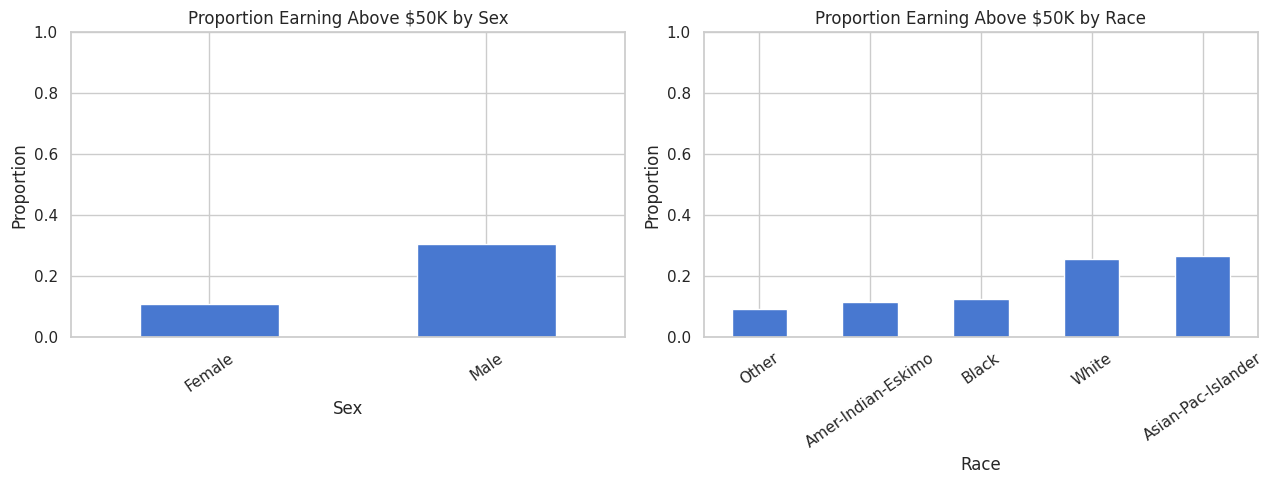

In [215]:
eda_df = df.copy()

eda_df["income"] = (
    eda_df["income"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.$", "", regex=True)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, attribute in zip(axes, ["sex", "race"]):
    income_rates = pd.crosstab(
        eda_df[attribute],
        eda_df["income"],
        normalize="index"
    )

    if ">50K" in income_rates.columns:
        income_rates[">50K"].sort_values().plot(
            kind="bar",
            ax=ax
        )

    ax.set_title(f"Proportion Earning Above $50K by {attribute.title()}")
    ax.set_xlabel(attribute.title())
    ax.set_ylabel("Proportion")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


The proportion of individuals earning above $50K is higher among males (approximately 30%) than females (approximately 10%). Across racial groups, Asian-Pac-Islander and White individuals show the highest proportions, at approximately 26% and 25%, respectively. Black individuals, Amer-Indian-Eskimo individuals, and those classified as Other have lower proportions, ranging from approximately 9% to 12%.

These differences indicate variations in income outcomes across sex and racial groups in the dataset. However, the chart shows associations rather than causes; further analysis is needed to assess whether these differences persist after accounting for other factors and when evaluating model fairness.

## 6 Train-Test Split

### 6.1 Splitting Strategy

In [216]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Align sensitive attributes to the same train/test rows
sensitive_train = sensitive_features.loc[X_train.index].copy()
sensitive_test = sensitive_features.loc[X_test.index].copy()

assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert X_train.index.equals(sensitive_train.index)
assert X_test.index.equals(sensitive_test.index)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).sort_index().round(3))


Training samples: 26029
Testing samples: 6508

Training class proportions:


,proportion
income,
0,0.759
1,0.241



Testing class proportions:


,proportion
income,
0,0.759
1,0.241


The dataset was split into 26,029 training samples and 6,508 testing samples. Both sets retain the same class proportions: 75.9% of individuals earn <=50K and 24.1% earn >50K.

This consistency indicates that stratified sampling preserved the target distribution across both sets, supporting a more reliable evaluation of model performance on unseen data.

### 6.2 Data preprocessing pipeline

In [217]:
# 1. Identify numerical and categorical features
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

# 2. Preprocess numerical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 3. Preprocess categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 4. Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# 5. Verify the setup
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total input features:", len(numeric_features) + len(categorical_features))
print("Numerical columns:", numeric_features)
print("Categorical columns:", categorical_features)
print("Combined preprocessor created successfully.")


Numerical features: 6
Categorical features: 6
Total input features: 12
Numerical columns: ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
Categorical columns: ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'native.country']
Combined preprocessor created successfully.


The dataset contains 12 input features, comprising 6 numerical and 6 categorical features. A combined preprocessing pipeline was created to handle missing numerical values through median imputation and scaling, and categorical values through most-frequent imputation and one-hot encoding, ensuring both feature types are prepared for model training.

## 7 Baseline Model Development

### 7.1 Baseline Model Training and Evaluation



In [218]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
baseline_predictions = pd.Series(
    y_pred,
    index=y_test.index,
    name="Baseline"
)

print("Baseline accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["<=50K", ">50K"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

if hasattr(model, "predict_proba"):
    y_probability = model.predict_proba(X_test)[:, 1]
    print("ROC-AUC:", round(roc_auc_score(y_test, y_probability), 4))


Baseline accuracy: 0.85

Classification report:
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      4940
        >50K       0.73      0.59      0.66      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.76      0.78      6508
weighted avg       0.84      0.85      0.84      6508

Confusion matrix:
[[4602  338]
 [ 638  930]]
ROC-AUC: 0.8981





The baseline Logistic Regression model achieved an accuracy of 85% and a ROC-AUC of 0.8981, indicating good overall classification performance and strong ability to distinguish between the two income classes. It performs better at identifying individuals earning <=50K (recall: 93%) than those earning >50K (recall: 59%).

The confusion matrix shows that the model correctly classified 4,602 lower-income and 930 higher-income individuals, but incorrectly classified 638 higher-income individuals as earning <=50K. This suggests that, despite good overall performance, the model misses a substantial proportion of individuals earning above $50K. The difference in class-specific recall highlights why accuracy alone is insufficient, particularly given the dataset's imbalanced income distribution.

### 7.2 Model Selection and Fairness Method Justification

#### Fairness Mitigation Approach

Logistic Regression is used as the baseline model because it provides an interpretable and reproducible classification approach and allows the effect of fairness mitigation to be compared against a clearly defined baseline.

For fairness mitigation, **ExponentiatedGradient with Equalized Odds** is selected using Fairlearn. Equalized Odds is appropriate for this analysis because it considers both true-positive and false-positive rates across demographic groups rather than focusing only on overall prediction rates.

The analysis considers **sex and race as separate sensitive attributes**. The same mitigation framework is therefore evaluated in two separate experiments: one using sex as the sensitive feature and another using race. This allows the effect of mitigation to be examined independently for each attribute.

The objective is not to assume that mitigation automatically produces a better model. Instead, the analysis compares predictive performance and group-level fairness before and after mitigation to identify potential fairness–performance trade-offs.


## 8. Baseline Model Evaluation

### 8.1 Classification Metrics

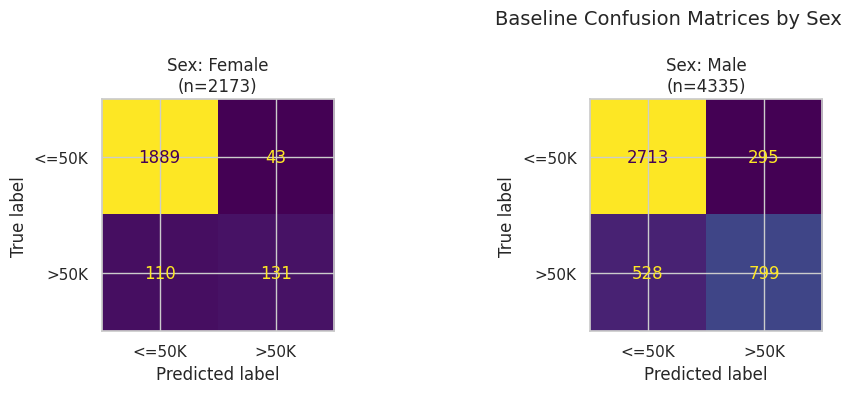

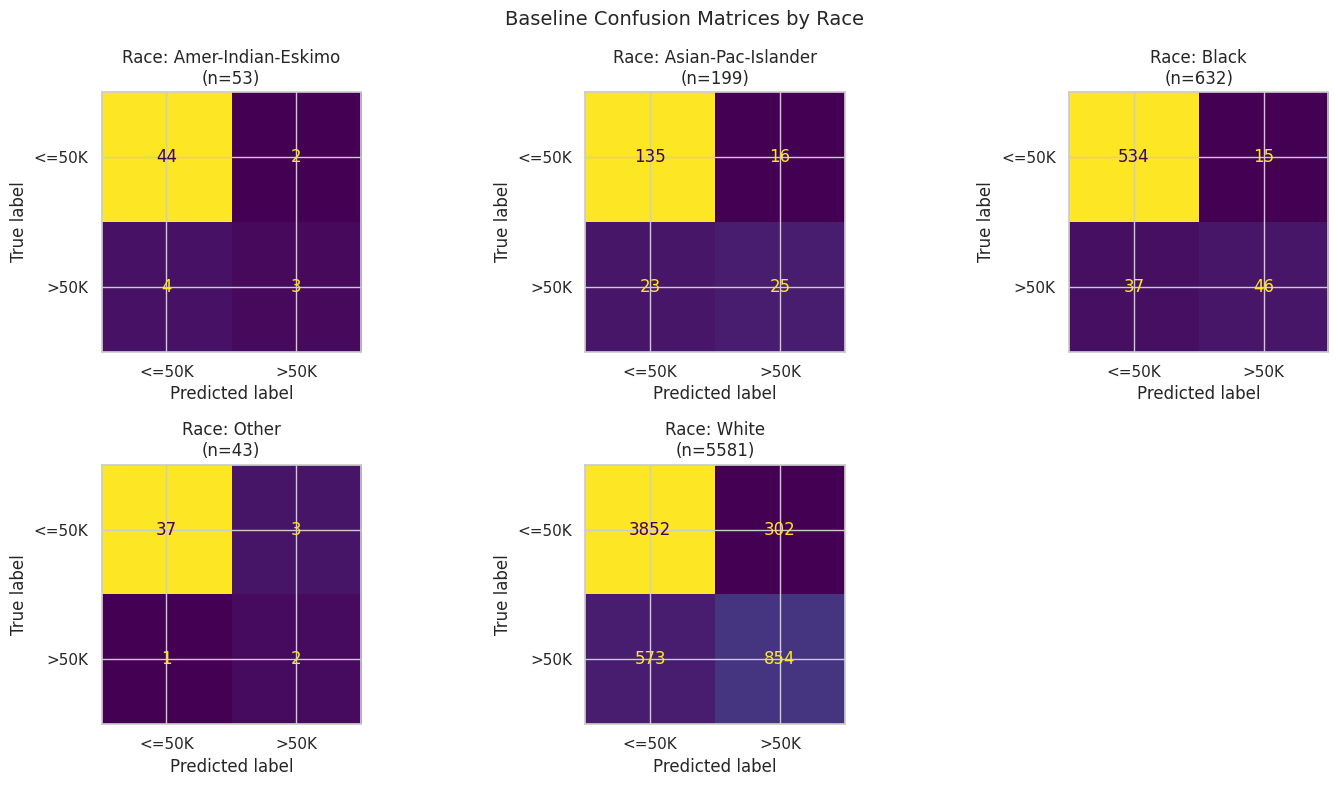

In [219]:
baseline_predictions = pd.Series(y_pred, index=y_test.index)

for attribute in ["sex", "race"]:
    groups = sensitive_test[attribute]
    unique_groups = sorted(groups.dropna().unique())

    cols = 3
    rows = math.ceil(len(unique_groups) / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(5 * cols, 4 * rows),
        squeeze=False
    )
    axes = axes.flatten()

    for i, group in enumerate(unique_groups):
        mask = groups == group

        ConfusionMatrixDisplay.from_predictions(
            y_test.loc[mask],
            baseline_predictions.loc[mask],
            labels=[0, 1],
            display_labels=["<=50K", ">50K"],
            values_format="d",
            ax=axes[i],
            colorbar=False
        )

        axes[i].set_title(
            f"{attribute.title()}: {group}\n(n={mask.sum()})"
        )

    for ax in axes[len(unique_groups):]:
        ax.set_visible(False)

    fig.suptitle(
        f"Baseline Confusion Matrices by {attribute.title()}",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()


**Baseline Performance Interpretation**

The race-specific confusion matrices show that the baseline model generally identifies individuals earning <=50K more accurately than those earning >50K. For the White group, it correctly classifies 3,852 lower-income and 854 higher-income individuals, but misclassifies 573 higher-income individuals as earning <=50K. For Black individuals, 534 lower-income and 46 higher-income cases are correctly classified, while 37 higher-income cases are incorrectly predicted as <=50K. Among Asian-Pac-Islander individuals, 135 lower-income and 25 higher-income cases are correctly classified, with 23 higher-income cases missed.


For the Amer-Indian-Eskimo group, the model correctly classifies 44 lower-income and 3 higher-income cases, while misclassifying 4 higher-income cases. For the Other group, it correctly classifies 37 lower-income and 2 higher-income cases; however, this group contains only 43 individuals, including just 3 who earn above $50K.

Overall, the matrices reveal differences in classification errors across racial groups, particularly in identifying individuals earning above $50K. However, the very small sample sizes for some groups mean their results should be interpreted cautiously. These findings motivate further subgroup fairness evaluation rather than establishing discrimination from the confusion matrices alone.

## 9. Measuring Bias / Unfairness

### 9.1 Fairness

Overall model accuracy alone is insufficient to determine whether a machine learning model treats demographic groups fairly. A model may achieve high accuracy while producing different prediction errors across demographic groups. Therefore, this project evaluates fairness using group-level performance metrics for the sensitive attributes sex and race.

1. True Positive Rate (TPR)

The True Positive Rate measures the proportion of individuals whose actual income is above $50K who are correctly predicted to earn above $50K.

\[
TPR = \frac{TP}{TP + FN}
\]


Differences in TPR across demographic groups indicate that the model may identify the favourable outcome more successfully for some groups than for others. A lower TPR means that a larger proportion of individuals who actually belong to the above-$50K income category are incorrectly classified as earning $50K or less.

2. False Positive Rate (FPR)

The False Positive Rate measures the proportion of individuals whose actual income is $50K or less who are incorrectly predicted to earn above $50K.

\[
FPR = \frac{FP}{FP + TN}
\]

Differences in FPR across groups indicate that the model produces false-positive predictions at different rates. This metric helps assess whether certain demographic groups experience a higher frequency of incorrect positive classifications.

3. False Negative Rate (FNR)

The False Negative Rate measures the proportion of individuals whose actual income is above $50K but who are incorrectly predicted to earn $50K or less.

\[
FNR = \frac{FN}{FN + TP} = 1 - TPR
\]

A higher FNR indicates that the model misses more individuals who actually belong to the above-$50K income category. Comparing FNR across demographic groups is important because unequal rates may reveal disparities in the model's ability to identify the positive class.

4. Disparate Impact Ratio (DIR)

The Disparate Impact Ratio compares the proportions of individuals receiving favourable predictions across two demographic groups. In this project, the favourable prediction is an income classification above $50K.

\[
DIR = \frac{P(\hat{Y}=1 \mid A=a)}
{P(\hat{Y}=1 \mid A=b)}
\]


Here, (a) and (b) represent two demographic groups, and (\hat{Y}=1) represents a predicted income above $50K. The ratio depends on which group is selected as the reference group.

A ratio closer to 1 indicates more similar favourable prediction rates between the two groups. A ratio below 1 indicates that the numerator group receives favourable predictions less frequently than the reference group. The commonly cited 0.8 threshold is a screening guideline used in some contexts, not a universal legal standard or definitive proof of fairness or discrimination.

5. Equalized Odds

Equalized Odds evaluates whether a model achieves similar True Positive Rates and False Positive Rates across demographic groups. It aims to reduce differences in both types of classification outcomes (Hardt et al., 2016; Fairlearn, n.d.-a).

In this project, Equalized Odds is used as the fairness constraint for the Fairlearn ExponentiatedGradient mitigation method. The baseline Logistic Regression model is compared with the mitigated models to examine whether group-level disparities are reduced.

A smaller difference in TPR and FPR across groups indicates better alignment with the Equalized Odds objective. However, improving these measures may involve trade-offs with accuracy, precision, or other performance measures.

Interpretation of Fairness Metrics

These metrics assess different dimensions of fairness and may lead to different conclusions. Differences in TPR, FPR, FNR, or favourable prediction rates identify potential disparities that require further investigation. However, these differences alone do not establish that discrimination has occurred.

Fairness results should be interpreted alongside group sample sizes, data quality, the context in which the model would be used, and the potential consequences of prediction errors. Smaller demographic groups may produce less stable estimates, so their results should be interpreted particularly cautiously.

## 10. Ethical Concerns and Responsible AI

1. Historical and Social Bias

The Adult Census Income dataset reflects income patterns and social conditions represented in historical census records. These patterns may be associated with longstanding inequalities in education, employment, and income. A model trained on such data may reproduce existing disparities rather than eliminate them. Consequently, predictive performance should be evaluated alongside potential social and demographic disparities.

2. Discrimination Based on Sensitive Attributes

Sex and race are sensitive attributes that require careful consideration in income prediction. Differences in prediction outcomes or error rates may indicate that some demographic groups experience less favourable model outcomes.

In this project, sex and race are excluded from the model's predictor features and retained separately for fairness auditing. However, excluding sensitive attributes does not necessarily eliminate bias because other variables, such as education, occupation, and marital status, may be associated with demographic differences and act as proxies for sensitive characteristics.

3. Unequal Errors and Potential Harm

False negatives occur when individuals whose recorded income is above $50K are predicted to earn $50K or less. False positives occur when individuals whose recorded income is $50K or less are predicted to earn above $50K.

If these errors occur at different rates across demographic groups, the model may create unequal risks or produce misleading conclusions for particular groups. In a real-world application, the consequences would depend on how the predictions are used. Income predictions should not be treated as definitive evidence about an individual's financial circumstances.

4. Representation and Data Quality

The dataset contains substantially different numbers of observations across demographic categories. For example, White individuals account for 27,795 observations, while the Other and Amer-Indian-Eskimo categories contain only 271 and 311 observations, respectively.

These differences in representation may affect the reliability of group-level fairness estimates, particularly for smaller groups. Missing values, duplicate records, inconsistent labels, and other data-quality issues can also influence model results. Appropriate data cleaning, transparent preprocessing, and reporting of subgroup sample sizes are therefore essential.

5. Privacy and Responsible Data Use

Demographic and income information should be handled responsibly, particularly when used in real-world business applications. Access should be restricted to authorised users, and data should be processed only for legitimate purposes in accordance with applicable data-protection requirements.

Sensitive attributes collected or retained for fairness auditing should be protected through appropriate access controls and data-governance procedures. Fairness evaluation should not create unnecessary exposure of personal information.

6. Transparency, Accountability, and Fairness Trade-offs

High overall accuracy does not guarantee that a model is fair across demographic groups. Different fairness criteria may produce different conclusions, and improving one fairness measure may affect predictive performance or other error rates.

Organisations should document their selected fairness objectives, explain the limitations of the model, monitor outcomes over time, and maintain appropriate human oversight when predictions influence consequential decisions. Fairness mitigation should be evaluated empirically rather than assumed to eliminate all forms of bias.

Why Fairness Evaluation Matters

The purpose of this project is to investigate whether a Logistic Regression model produces different prediction outcomes across sex and race groups and to evaluate whether a fairness-constrained method can reduce measured disparities.

The baseline model provides a reference point for predictive performance and subgroup error rates. The Fairlearn ExponentiatedGradient method with an Equalized Odds constraint is then used to assess whether the measured differences in TPR and FPR can be reduced. The comparison should consider both fairness outcomes and predictive performance, including accuracy, precision, recall, and F1-score.

Ultimately, this analysis does not assume that every observed difference proves discrimination or that fairness mitigation guarantees an unbiased model. Instead, it uses measurable evidence to identify potential risks, examine trade-offs, and support more transparent and responsible machine learning development.


Any real-world deployment would require additional legal, ethical, privacy and governance assessment, together with appropriate human oversight and ongoing monitoring.


## 11. Fairness Mitigation Methodology

### 11.1 Fairlearn and Exponentiated Gradient

In [220]:
fitted_preprocessor = model.named_steps["preprocessor"]

X_train_processed = fitted_preprocessor.transform(X_train)
X_test_processed = fitted_preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays only when needed
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

mitigated_models = {}
mitigated_predictions = {}

for attribute in ["sex", "race"]:
    print(f"Training Equalized Odds mitigation for {attribute}...")

    mitigator = ExponentiatedGradient(
        estimator=LogisticRegression(
            max_iter=1000,
            random_state=42
        ),
        constraints=EqualizedOdds(),
        eps=0.01
    )

    mitigator.fit(
        X_train_processed,
        y_train,
        sensitive_features=sensitive_train[attribute]
    )

    # Make randomized predictions reproducible
    predictions = mitigator.predict(
        X_test_processed,
        random_state=42
    )

    mitigated_models[attribute] = mitigator
    mitigated_predictions[attribute] = pd.Series(
        predictions,
        index=y_test.index,
        name=f"Mitigated_{attribute}"
    )

print("\nMitigation training completed.")
print("Available prediction keys:", list(mitigated_predictions.keys()))

assert set(mitigated_predictions.keys()) == {"sex", "race"}
assert all(
    len(pred) == len(y_test)
    for pred in mitigated_predictions.values()
)


Training Equalized Odds mitigation for sex...
Training Equalized Odds mitigation for race...

Mitigation training completed.
Available prediction keys: ['sex', 'race']


Both fairness mitigation models were trained successfully: one targeting sex-based fairness and the other targeting race-based fairness. The next step is to evaluate each model against the baseline using predictive performance metrics and group fairness measures, particularly the Equalized Odds Difference. This comparison will help determine whether either mitigation approach reduces disparities while maintaining acceptable predictive performance.

Equalized Odds was selected because the baseline evaluation identified differences in true positive and false positive rates across sex and race groups. The constraint aims to reduce these differences by accounting for both types of classification outcomes during mitigation. However, achieving this objective can involve trade-offs with overall predictive performance and other fairness measures. The effectiveness of mitigation must therefore be assessed empirically using the same held-out test set and multiple group-level metrics. Applying an Equalized Odds constraint does not guarantee that all demographic disparities will be eliminated.

### 11.2 Sex-Based Mitigation & Race-Based Mitigation

In [221]:
fairness_results_list = []

for attribute in ["sex", "race"]:
    groups = sensitive_test[attribute]

    for group in sorted(groups.dropna().unique()):
        mask = groups == group

        actual = y_test.loc[mask]
        predicted = baseline_predictions.loc[mask]

        tn, fp, fn, tp = confusion_matrix(
            actual,
            predicted,
            labels=[0, 1]
        ).ravel()

        total = tn + fp + fn + tp

        fairness_results_list.append({
            "Attribute": attribute,
            "Group": group,
            "Samples": total,
            "TPR": tp / (tp + fn) if (tp + fn) else np.nan,
            "FPR": fp / (fp + tn) if (fp + tn) else np.nan,
            "FNR": fn / (fn + tp) if (fn + tp) else np.nan,
            "FDR": fp / (fp + tp) if (fp + tp) else np.nan,
            "FOR": fn / (fn + tn) if (fn + tn) else np.nan,
            "Predicted >50K Rate": predicted.mean()
        })

fairness_results = pd.DataFrame(fairness_results_list)

display(fairness_results.round(3))



,Attribute,Group,Samples,TPR,FPR,FNR,FDR,FOR,Predicted >50K Rate
0,sex,Female,2173,0.544,0.022,0.456,0.247,0.055,0.080
1,sex,Male,4335,0.602,0.098,0.398,0.270,0.163,0.252
2,race,Amer-Indian-Eskimo,53,0.429,0.043,0.571,0.400,0.083,0.094
3,race,Asian-Pac-Islander,199,0.521,0.106,0.479,0.390,0.146,0.206
4,race,Black,632,0.554,0.027,0.446,0.246,0.065,0.097
5,race,Other,43,0.667,0.075,0.333,0.600,0.026,0.116
6,race,White,5581,0.598,0.073,0.402,0.261,0.129,0.207


The group-level fairness results show differences in prediction outcomes across sex and racial groups. Among females, the True Positive Rate (TPR) is 54.4%, compared with 60.2% among males, while the False Positive Rate (FPR) is 2.2% for females and 9.8% for males. The predicted above-$50K rate is also higher for males (25.2%) than females (8.0%), indicating a substantial difference in favourable prediction rates.

Across racial groups, the TPR ranges from 42.9% for Amer-Indian-Eskimo individuals to 66.7% for the Other category. The FPR is highest among Asian-Pac-Islander individuals (10.6%) and lowest among Black individuals (2.7%). The predicted above-$50K rate ranges from 9.4% for Amer-Indian-Eskimo individuals to 20.7% for White individuals, with Asian-Pac-Islander individuals close behind at 20.6%.

These results identify potential disparities in classification errors and favourable prediction rates across demographic groups. However, the Other category contains only 43 individuals, and the Amer-Indian-Eskimo category contains 53, so their metrics may be unstable. These differences warrant further investigation but do not, by themselves, prove discrimination. The baseline results should next be compared with the Equalized Odds-mitigated models to determine whether group-level TPR and FPR disparities have decreased and what trade-offs, if any, occur in predictive performance.

## 12. Mitigated Model Evaluation

### 12.1 Baseline Fairness

In [222]:
baseline_predictions = pd.Series(y_pred, index=y_test.index)

for attribute in ["sex", "race"]:
    print(f"\n{'=' * 50}")
    print(f"BASELINE FAIRNESS: {attribute.upper()}")
    print(f"{'=' * 50}")

    metric_frame = MetricFrame(
        metrics={
            "Selection Rate": selection_rate,
            "True Positive Rate": true_positive_rate,
            "False Positive Rate": false_positive_rate
        },
        y_true=y_test,
        y_pred=baseline_predictions,
        sensitive_features=sensitive_test[attribute]
    )

    print("Metrics by group:")
    display(metric_frame.by_group.round(3))

    print("Difference between highest and lowest group values:")
    display(metric_frame.difference().round(3))



BASELINE FAIRNESS: SEX
Metrics by group:


,Selection Rate,True Positive Rate,False Positive Rate
sex,,,
Female,0.080,0.544,0.022
Male,0.252,0.602,0.098


Difference between highest and lowest group values:


,0
Selection Rate,0.172
True Positive Rate,0.059
False Positive Rate,0.076



BASELINE FAIRNESS: RACE
Metrics by group:


,Selection Rate,True Positive Rate,False Positive Rate
race,,,
Amer-Indian-Eskimo,0.094,0.429,0.043
Asian-Pac-Islander,0.206,0.521,0.106
Black,0.097,0.554,0.027
Other,0.116,0.667,0.075
White,0.207,0.598,0.073


Difference between highest and lowest group values:


,0
Selection Rate,0.113
True Positive Rate,0.238
False Positive Rate,0.079


### Baseline Fairness Analysis — Interpretation

The baseline fairness evaluation reveals differences in prediction outcomes across sex and race groups. For sex, the selection rate is 25.2% for males and 8.0% for females, resulting in a difference of 17.2 percentage points. The true positive rate (TPR) difference is 5.8 percentage points, while the false positive rate (FPR) difference is 7.6 percentage points. These results indicate that the model's prediction rates and classification errors vary between males and females.

Across racial groups, the selection-rate difference is 11.3 percentage points, while the TPR difference is 23.8 percentage points. The FPR difference is 7.9 percentage points. The larger difference in TPR indicates variation in how effectively the model identifies individuals earning above $50,000 across racial groups.

Overall, the baseline model exhibits disparities in selection rates and classification error rates across the evaluated demographic groups. These results provide a reference point for assessing the effects of Equalized Odds mitigation. However, differences in these metrics alone do not establish that discrimination has occurred. The findings should be interpreted cautiously, particularly for smaller demographic groups, because their estimates may be less stable.

### 12.2 Group-level metrics after mitigation

In [223]:
if "fairness_results" not in globals():
    raise RuntimeError(
        "fairness_results is missing. Run the cell "
         "that creates fairness_results first."
    )

for attribute in ["sex", "race"]:
    print(f"\nBaseline fairness metrics by {attribute}:")

    display(
        fairness_results.loc[
            fairness_results["Attribute"] == attribute,
            [
                "Group",
                "Samples",
                "TPR",
                "FPR",
                "FNR",
                "FDR",
                "FOR",
                "Predicted >50K Rate"
            ]
        ].round(3)
    )



Baseline fairness metrics by sex:


,Group,Samples,TPR,FPR,FNR,FDR,FOR,Predicted >50K Rate
0,Female,2173,0.544,0.022,0.456,0.247,0.055,0.080
1,Male,4335,0.602,0.098,0.398,0.270,0.163,0.252



Baseline fairness metrics by race:


,Group,Samples,TPR,FPR,FNR,FDR,FOR,Predicted >50K Rate
2,Amer-Indian-Eskimo,53,0.429,0.043,0.571,0.400,0.083,0.094
3,Asian-Pac-Islander,199,0.521,0.106,0.479,0.390,0.146,0.206
4,Black,632,0.554,0.027,0.446,0.246,0.065,0.097
5,Other,43,0.667,0.075,0.333,0.600,0.026,0.116
6,White,5581,0.598,0.073,0.402,0.261,0.129,0.207




The baseline fairness metrics show that males have a higher predicted above-$50K rate (25.2%) than females (8.0%). The TPR is also higher for males (60.2%) than females (54.4%), while the FPR is 9.8% for males compared with 2.2% for females.

Across racial groups, White individuals have a predicted above-$50K rate of 20.7%, similar to Asian-Pac-Islander individuals at 20.6%. The TPR ranges from 42.9% for Amer-Indian-Eskimo individuals to 66.7% for the Other category, while the FPR is highest for Asian-Pac-Islander individuals at 10.6%. The Other group has a high FDR of 60.0%, but it contains only 43 individuals, so this estimate should be interpreted cautiously.

Overall, the results reveal differences in favourable prediction rates and classification errors across sex and race groups. These baseline metrics provide a reference for evaluating the impact of Equalized Odds mitigation, but the observed disparities alone do not prove discrimination.

### 12.3 Model Comparison and Trade-offs



In [224]:
models_to_evaluate = {
    "Baseline": baseline_predictions,
    "Mitigated (sex)": mitigated_predictions["sex"],
    "Mitigated (race)": mitigated_predictions["race"]
}

comparison = []
group_results = {}

for model_name, predictions in models_to_evaluate.items():

    # Overall predictive performance
    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    }

    # Evaluate each model against both sensitive attributes
    for attribute in ["sex", "race"]:
        groups = sensitive_test[attribute]

        row[f"EO Difference ({attribute})"] = (
            equalized_odds_difference(
                y_test,
                predictions,
                sensitive_features=groups
            )
        )

        frame = MetricFrame(
            metrics={
                "Selection Rate": selection_rate,
                "True Positive Rate": true_positive_rate,
                "False Positive Rate": false_positive_rate
            },
            y_true=y_test,
            y_pred=predictions,
            sensitive_features=groups
        )

        group_results[(model_name, attribute)] = frame.by_group

    comparison.append(row)

comparison_df = pd.DataFrame(comparison)

print("Overall performance and fairness comparison:")
display(comparison_df.round(3))

for (model_name, attribute), group_metrics in group_results.items():
    print(f"\n{model_name} — group metrics by {attribute}:")
    display(group_metrics.round(3))


Overall performance and fairness comparison:


,Model,Accuracy,Precision,Recall,F1-score,EO Difference (sex),EO Difference (race)
0,Baseline,0.850,0.733,0.593,0.656,0.076,0.238
1,Mitigated (sex),0.838,0.716,0.540,0.616,0.048,0.193
2,Mitigated (race),0.835,0.715,0.525,0.605,0.045,0.381



Baseline — group metrics by sex:


,Selection Rate,True Positive Rate,False Positive Rate
sex,,,
Female,0.080,0.544,0.022
Male,0.252,0.602,0.098



Baseline — group metrics by race:


...

,Selection Rate,True Positive Rate,False Positive Rate
race,,,
Amer-Indian-Eskimo,0.113,0.714,0.022
Asian-Pac-Islander,0.191,0.521,0.086
Black,0.104,0.530,0.040
Other,0.186,0.667,0.150
White,0.191,0.540,0.071



Mitigated (race) — group metrics by sex:


,Selection Rate,True Positive Rate,False Positive Rate
sex,,,
Female,0.096,0.552,0.039
Male,0.218,0.520,0.084



Mitigated (race) — group metrics by race:


,Selection Rate,True Positive Rate,False Positive Rate
race,,,
Amer-Indian-Eskimo,0.075,0.286,0.043
Asian-Pac-Islander,0.141,0.438,0.046
Black,0.119,0.542,0.055
Other,0.116,0.667,0.075
White,0.186,0.528,0.069


Sex TPR/FPR charts and race TPR/FPR charts

In [225]:
model_order = list(models_to_evaluate.keys())

sex_rows = []
race_rows = []

for model_name in model_order:

    for group, metrics in group_results[
        (model_name, "sex")
    ].iterrows():
        sex_rows.append({
            "Model": model_name,
            "Group": str(group),
            "TPR": metrics["True Positive Rate"],
            "FPR": metrics["False Positive Rate"]
        })

    for group, metrics in group_results[
        (model_name, "race")
    ].iterrows():
        race_rows.append({
            "Model": model_name,
            "Group": str(group),
            "TPR": metrics["True Positive Rate"],
            "FPR": metrics["False Positive Rate"]
        })

sex_metric_plot = pd.DataFrame(sex_rows)
race_metric_plot = pd.DataFrame(race_rows)

The code consolidates group-level True Positive Rate (TPR) and False Positive Rate (FPR) metrics for each evaluated model, separately for sex and race. The resulting DataFrames provide a structured basis for comparing error-rate disparities across demographic groups and evaluating the effects of fairness mitigation. These comparisons support the subsequent assessment of model performance and fairness trade-offs.

### 12.4 Predictive Performance vs. Fairness

**Predictive-performance chart**

**Group level metrics after mitigation**

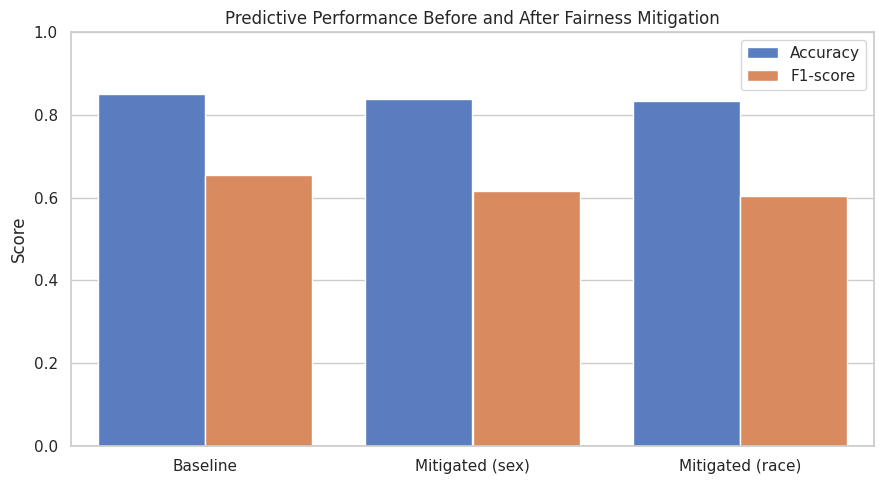

In [226]:
performance_plot = comparison_df[
    ["Model", "Accuracy", "F1-score"]
].melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=performance_plot,
    x="Model",
    y="Score",
    hue="Metric",
    errorbar=None
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("")
plt.title("Predictive Performance Before and After Fairness Mitigation")
plt.legend(title="")
plt.tight_layout()
plt.show()

The comparison shows that the baseline Logistic Regression model achieved the highest predictive performance, with an accuracy of 0.850 and an F1-score of 0.656. After applying sex mitigation, accuracy decreased to 0.838 and the F1-score to 0.616. The race-mitigated model recorded an accuracy of 0.835 and an F1-score of 0.605, representing the lowest predictive performance among the three models.

These results indicate a trade-off between predictive performance and fairness mitigation. Although both mitigation approaches resulted in small decreases in accuracy, the reductions in F1-score were more noticeable. The baseline model therefore provides the strongest predictive-performance benchmark, while the mitigated models must be evaluated alongside their fairness results. Model selection should consider both predictive effectiveness and fairness across demographic groups rather than accuracy alone.

Precision decreased from 0.733 in the baseline model to 0.716 after sex-based mitigation and 0.715 after race-based mitigation. Recall also decreased, from 0.593 to 0.540 and 0.525, respectively. This indicates that the mitigated models identified a smaller proportion of actual positive cases in the test set. These changes should be considered alongside the improvements or deterioration in the relevant fairness measures when assessing the overall trade-off between predictive performance and fairness.

In [227]:
for model_name, predictions in models_to_evaluate.items():
    print(
        model_name,
        "Sex EO difference:",
        equalized_odds_difference(
            y_test,
            predictions,
            sensitive_features=sensitive_test["sex"]
        ),
        "Race EO difference:",
        equalized_odds_difference(
            y_test,
            predictions,
            sensitive_features=sensitive_test["race"]
        )
    )

Baseline Sex EO difference: 0.07581507973217039 Race EO difference: 0.23809523809523808
Mitigated (sex) Sex EO difference: 0.048132154705807007 Race EO difference: 0.19345238095238093
Mitigated (race) Sex EO difference: 0.045289166776793975 Race EO difference: 0.38095238095238093


Equalized Odds chart

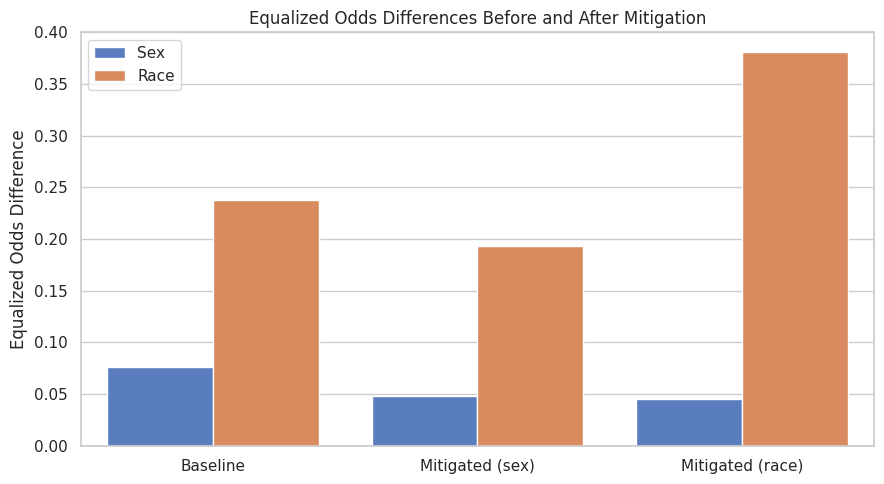

In [228]:
eo_plot = comparison_df[
    ["Model", "EO Difference (sex)", "EO Difference (race)"]
].rename(columns={
    "EO Difference (sex)": "Sex",
    "EO Difference (race)": "Race"
}).melt(
    id_vars="Model",
    var_name="Sensitive Attribute",
    value_name="EO Difference"
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=eo_plot,
    x="Model",
    y="EO Difference",
    hue="Sensitive Attribute",
    errorbar=None
)

plt.ylabel("Equalized Odds Difference")
plt.xlabel("")
plt.title("Equalized Odds Differences Before and After Mitigation")
plt.legend(title="")
plt.tight_layout()
plt.show()

The comparison shows that the baseline model has an Equalized Odds Difference of 0.076 for sex and 0.238 for race. After applying sex mitigation, these values decrease to 0.048 and 0.193, respectively, indicating improvements in the measured fairness outcomes for both attributes. In contrast, race mitigation reduces the difference for sex to 0.045 but increases the difference for race to 0.381.

These findings demonstrate that the effectiveness of fairness mitigation depends on the protected attribute being evaluated. Although race mitigation achieves the lowest Equalized Odds Difference for sex, it produces the largest difference for race among the three models. Sex mitigation therefore provides the more balanced result across the two reported attributes. However, these aggregate metrics do not establish that every demographic subgroup benefits equally, so the group-level TPR and FPR results must also be considered before drawing conclusions about overall fairness.

In [229]:
for model_name, predictions in models_to_evaluate.items():
    print(f"\n{model_name}")
    print("Race EO:",
          equalized_odds_difference(
              y_test,
              predictions,
              sensitive_features=sensitive_test["race"]
          ))
    print("Predicted positives:", predictions.sum())



Baseline
Race EO: 0.23809523809523808
Predicted positives: 1268

Mitigated (sex)
Race EO: 0.19345238095238093
Predicted positives: 1183

Mitigated (race)
Race EO: 0.38095238095238093
Predicted positives: 1151


In [230]:
for model_name, predictions in models_to_evaluate.items():
    print(f"\n--- {model_name} ---")

    results = []

    for group in sorted(sensitive_test["race"].dropna().unique()):
        mask = sensitive_test["race"].eq(group)

        results.append({
            "Race": group,
            "TPR": true_positive_rate(
                y_test[mask], predictions[mask]
            ),
            "FPR": false_positive_rate(
                y_test[mask], predictions[mask]
            )
        })

    print(pd.DataFrame(results).round(3).to_string(index=False))


--- Baseline ---
              Race   TPR   FPR
Amer-Indian-Eskimo 0.429 0.043
Asian-Pac-Islander 0.521 0.106
             Black 0.554 0.027
             Other 0.667 0.075
             White 0.598 0.073

--- Mitigated (sex) ---
              Race   TPR   FPR
Amer-Indian-Eskimo 0.714 0.022
Asian-Pac-Islander 0.521 0.086
             Black 0.530 0.040
             Other 0.667 0.150
             White 0.540 0.071

--- Mitigated (race) ---
              Race   TPR   FPR
Amer-Indian-Eskimo 0.286 0.043
Asian-Pac-Islander 0.438 0.046
             Black 0.542 0.055
             Other 0.667 0.075
             White 0.528 0.069


### 12.5 Comparison Visualisations

**True Positive Rate by Sex**

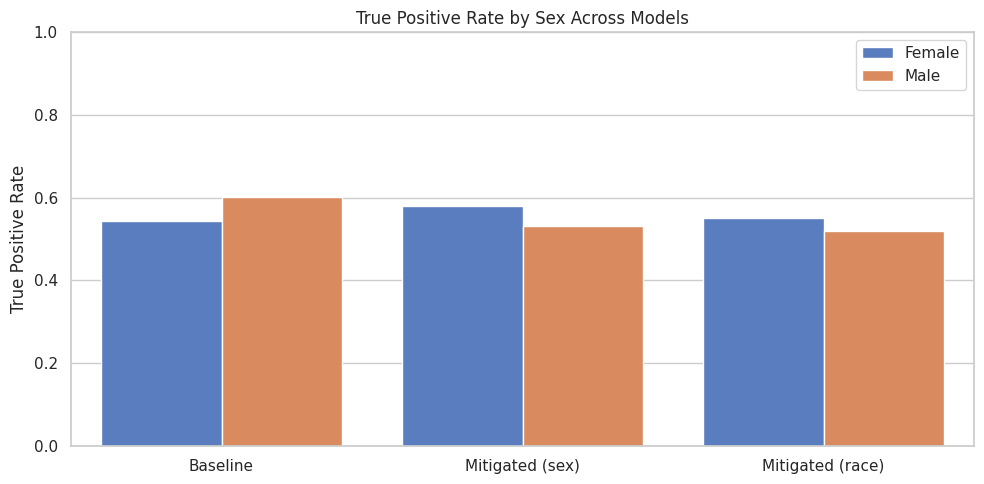

In [231]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=sex_metric_plot,
    x="Model",
    y="TPR",
    hue="Group",
    order=model_order,
    errorbar=None
)

plt.ylim(0, 1)
plt.ylabel("True Positive Rate")
plt.xlabel("")
plt.title("True Positive Rate by Sex Across Models")
plt.legend(title="")
plt.tight_layout()
plt.show()

The baseline model achieved a True Positive Rate (TPR) of 0.544 for females and 0.602 for males, indicating a difference of 0.058 between the two groups. After applying sex mitigation, the female TPR increased to 0.581, while the male TPR decreased to 0.533. This reversed the direction of the difference, with females having a higher TPR than males. The race-mitigated model recorded TPR values of 0.552 for females and 0.520 for males, also showing a higher TPR for females.

These results suggest that both mitigation approaches changed the distribution of true positive outcomes across sex groups. Sex mitigation produced the largest female TPR among the three models, while the race-mitigated model produced the smallest absolute TPR gap between females and males. However, TPR alone does not provide a complete assessment of fairness because it does not account for false positive rates. Therefore, these results should be interpreted alongside the FPR comparison and Equalized Odds Difference.

**False Positive Rate by Sex**

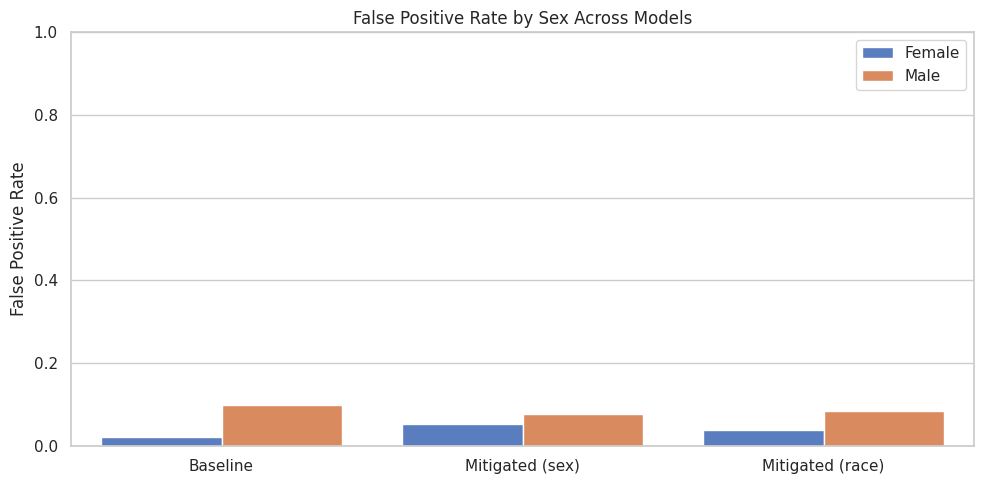

In [232]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=sex_metric_plot,
    x="Model",
    y="FPR",
    hue="Group",
    order=model_order,
    errorbar=None
)

plt.ylim(0, 1)
plt.ylabel("False Positive Rate")
plt.xlabel("")
plt.title("False Positive Rate by Sex Across Models")
plt.legend(title="")
plt.tight_layout()
plt.show()

The baseline model recorded a False Positive Rate (FPR) of 0.022 for females and 0.098 for males, indicating a difference of 0.076 between the two groups. After sex mitigation, the female FPR increased to 0.054, while the male FPR decreased to 0.077, reducing the gap to 0.023. The race-mitigated model recorded FPR values of 0.039 for females and 0.084 for males, resulting in a gap of 0.045.

These results indicate that sex mitigation produced the smallest FPR gap between females and males among the three models. However, the improvement was accompanied by an increase in the female FPR compared with the baseline. This illustrates that reducing disparities between groups does not necessarily mean that error rates decrease for every group. Therefore, FPR should be evaluated alongside TPR, predictive performance, and other fairness metrics to obtain a more comprehensive assessment.

**True Positive Rate Across Race Groups**

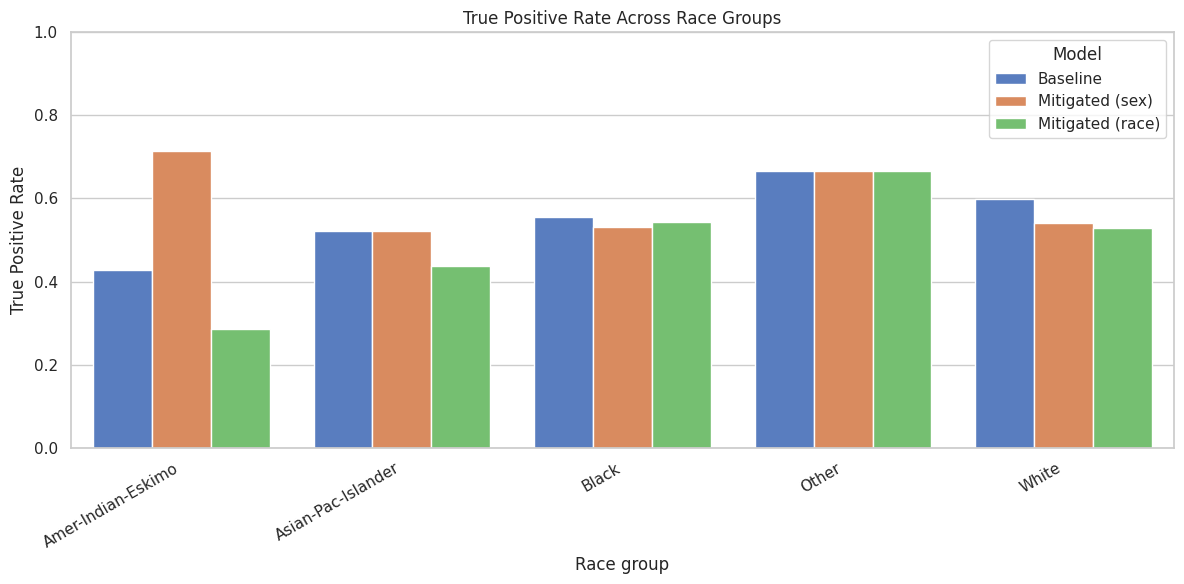

In [233]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=race_metric_plot,
    x="Group",
    y="TPR",
    hue="Model",
    hue_order=model_order,
    errorbar=None
)

plt.ylim(0, 1)
plt.ylabel("True Positive Rate")
plt.xlabel("Race group")
plt.title("True Positive Rate Across Race Groups")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

The True Positive Rate (TPR) varies across race groups and models, indicating that the effects of mitigation are not consistent across all demographic groups. In the baseline model, the TPR ranges from 0.429 for the American Indian/Alaska Native group to 0.667 for the Other group. After sex mitigation, the TPR for the American Indian/Alaska Native group increases to 0.714, while the White group's TPR decreases from 0.598 to 0.540. After race mitigation, the TPR for the American Indian/Alaska Native group decreases to 0.286, and the Asian/Pacific Islander group's TPR decreases from 0.521 to 0.438.

These findings show that mitigation can produce different outcomes for different demographic groups. Although sex mitigation increases the TPR for the American Indian/Alaska Native group, race mitigation produces a substantially lower TPR for the same group. The TPR for the Other group remains unchanged at 0.667 across all three models. Therefore, fairness improvements should not be assumed to benefit every race group equally. These results should be evaluated alongside FPR differences, group sample sizes, and the overall Equalized Odds Difference before selecting a model.

**False Positive Rate Across Race Groups**

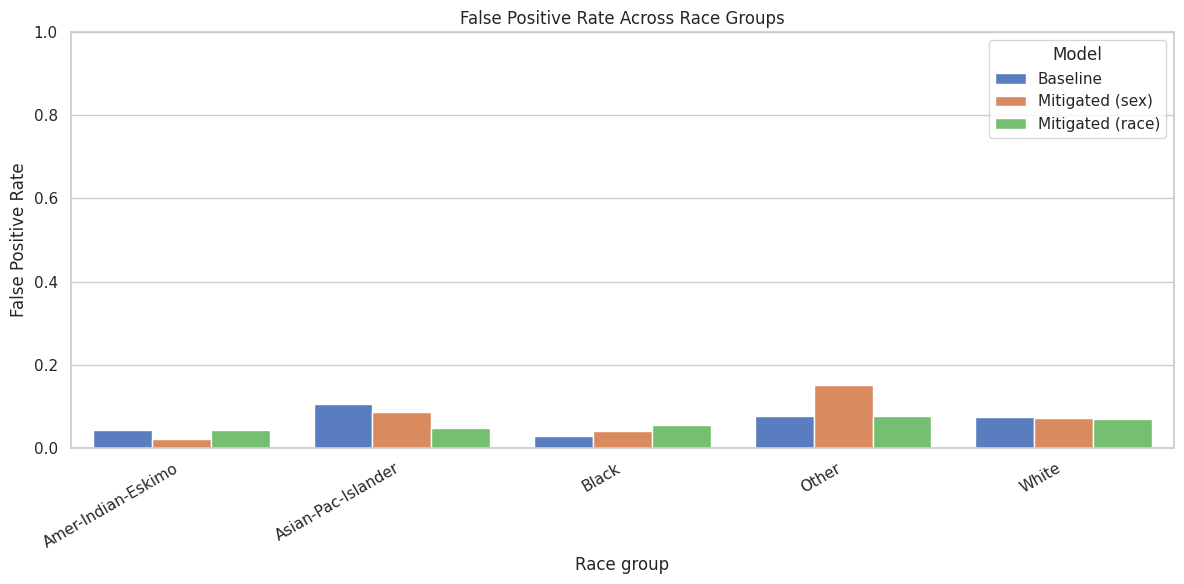

In [234]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=race_metric_plot,
    x="Group",
    y="FPR",
    hue="Model",
    hue_order=model_order,
    errorbar=None
)

plt.ylim(0, 1)
plt.ylabel("False Positive Rate")
plt.xlabel("Race group")
plt.title("False Positive Rate Across Race Groups")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

The False Positive Rate (FPR) varies across race groups and models, showing that the effects of fairness mitigation differ between demographic groups. In the baseline model, the Asian/Pacific Islander group has the highest FPR at 0.106, while the Black group has the lowest at 0.027. After sex mitigation, the FPR for the Other group increases from 0.075 to 0.150, while the Asian/Pacific Islander group's FPR decreases to 0.086. After race mitigation, the Asian/Pacific Islander group's FPR decreases further to 0.046, whereas the Black group's FPR increases to 0.055.

These results demonstrate that a mitigation method may reduce false positive errors for some groups while increasing them for others. Race mitigation substantially reduces the FPR for the Asian/Pacific Islander group, but it does not produce the lowest FPR for every race group. The increase in the Other group's FPR under sex mitigation also highlights the importance of examining subgroup-level outcomes rather than relying only on aggregate fairness measures. Therefore, FPR results should be interpreted alongside TPR, Equalized Odds Difference, and predictive performance when evaluating the models.

**sample sizes for sex and race**

In [235]:
# Combine test labels and sensitive attributes
group_data = pd.DataFrame({
    "actual": y_test,
    "sex": sensitive_test["sex"],
    "race": sensitive_test["race"]
})

print("Sample sizes by sex:")
display(group_data["sex"].value_counts().rename("Sample Size").to_frame())

print("Sample sizes by race:")
display(group_data["race"].value_counts().rename("Sample Size").to_frame())

Sample sizes by sex:


,Sample Size
sex,
Male,4335
Female,2173


Sample sizes by race:


,Sample Size
race,
White,5581
Black,632
Asian-Pac-Islander,199
Amer-Indian-Eskimo,53
Other,43


The test set contains 6,508 observations, including 4,335 males and 2,173 females. The racial distribution is uneven, with 5,581 White individuals, 632 Black individuals, 199 Asian-Pac-Islander individuals, 53 Amer-Indian-Eskimo individuals, and 43 individuals classified as Other. These differences in subgroup size are important when interpreting fairness metrics. Estimates for smaller groups may be more sensitive to a small number of classification changes and should therefore be interpreted cautiously. The analysis considers subgroup sample sizes alongside TPR and FPR to provide a more transparent assessment of model fairness.

**Disparate Impact Ratio (DIR)**

In [236]:
# Compare favourable prediction rates for females and males
sex_values = sensitive_test["sex"].to_numpy()

dir_results = []

for model_name, predictions in models_to_evaluate.items():
    prediction_values = np.asarray(predictions)

    female_rate = prediction_values[sex_values == "Female"].mean()
    male_rate = prediction_values[sex_values == "Male"].mean()

    dir_ratio = female_rate / male_rate if male_rate > 0 else np.nan

    dir_results.append({
        "Model": model_name,
        "Female Selection Rate": female_rate,
        "Male Selection Rate": male_rate,
        "DIR (Female / Male)": dir_ratio
    })

# Create and display the table AFTER collecting the results
dir_table = pd.DataFrame(dir_results)
print(dir_table.round(3).to_string(index=False))

           Model  Female Selection Rate  Male Selection Rate  DIR (Female / Male)
        Baseline                  0.080                0.252                0.317
 Mitigated (sex)                  0.112                0.217                0.518
Mitigated (race)                  0.096                0.218                0.440


The Disparate Impact Ratio (DIR) was calculated by dividing the female selection rate by the male selection rate for each model. The baseline model produced a DIR of 0.317, indicating that the female selection rate was approximately 31.7% of the male selection rate. After sex-based mitigation, the ratio increased to 0.518, while race-based mitigation produced a ratio of 0.440. Both mitigation approaches therefore moved the selection-rate ratio closer to 1, with sex-based mitigation showing the greater improvement in this comparison.

However, neither mitigated model eliminated the observed disparity in selection rates. The commonly cited 0.80 threshold can be used as a screening reference in some contexts, but it is not a universal legal standard or proof of discrimination. These results should be interpreted alongside Equalized Odds Difference, subgroup error rates, predictive performance and sample sizes. Since DIR measures selection-rate differences rather than classification errors, it complements but does not replace the other fairness measures.

### 12.6 Overall Comparison of Predictive Performance and Fairness

Taken together, the results show that no single model performed best across all evaluation criteria. The baseline model achieved the highest predictive performance, with an accuracy of 0.850 and an F1-score of 0.656. However, its Equalized Odds Difference was 0.076 for sex and 0.238 for race, indicating differences in error-related outcomes between the corresponding demographic groups.

Sex-based mitigation reduced the Equalized Odds Difference to 0.048 for sex and 0.193 for race. Its Disparate Impact Ratio (DIR) also increased from 0.317 in the baseline model to 0.518, moving the female-to-male selection-rate ratio closer to 1. Race-based mitigation reduced the sex Equalized Odds Difference to 0.045, but the race difference increased to 0.381. Its DIR improved to 0.440, although the selection-rate disparity remained.

Considering these reported measures together, sex-based mitigation provided the more balanced result across the evaluated fairness criteria, while the baseline model retained the strongest predictive performance. Nevertheless, both mitigation approaches reduced predictive performance to some extent, and neither eliminated all measured disparities. These findings demonstrate why model selection should consider predictive performance, group-level error differences and selection-rate disparities together. The results apply to this dataset, test split and chosen fairness measures; further validation would be necessary before drawing conclusions about performance or fairness in other settings.

## 13. Prediction and Error Analysis

### 13.1 Changes in predictions

In [237]:
# Analyse prediction changes caused by fairness mitigation

flip_rows = []

for model_name in ["Mitigated (sex)", "Mitigated (race)"]:
    model_pred = models_to_evaluate[model_name]

    changed = model_pred.ne(baseline_predictions)

    flip_rows.append({
        "Mitigation": model_name,
        "Attribute": "Overall",
        "Group": "All test cases",
        "Samples": len(changed),
        "Changed predictions": int(changed.sum()),
        "Changed (%)": round(changed.mean() * 100, 2)
    })

    for attribute in ["sex", "race"]:
        for group in sorted(
            sensitive_test[attribute].dropna().unique()
        ):
            idx = sensitive_test.index[
                sensitive_test[attribute].eq(group)
            ]

            group_changed = model_pred.loc[idx].ne(
                baseline_predictions.loc[idx]
            )

            flip_rows.append({
                "Mitigation": model_name,
                "Attribute": attribute,
                "Group": group,
                "Samples": len(idx),
                "Changed predictions": int(group_changed.sum()),
                "Changed (%)": round(
                    group_changed.mean() * 100, 2
                )
            })

prediction_flip_df = pd.DataFrame(flip_rows)
display(prediction_flip_df)

,Mitigation,Attribute,Group,Samples,Changed predictions,Changed (%)
0,Mitigated (sex),Overall,All test cases,6508,303,4.66
1,Mitigated (sex),sex,Female,2173,120,5.52
2,Mitigated (sex),sex,Male,4335,183,4.22
3,Mitigated (sex),race,Amer-Indian-Eskimo,53,5,9.43
4,Mitigated (sex),race,Asian-Pac-Islander,199,9,4.52
5,Mitigated (sex),race,Black,632,27,4.27
6,Mitigated (sex),race,Other,43,3,6.98
7,Mitigated (sex),race,White,5581,259,4.64
8,Mitigated (race),Overall,All test cases,6508,345,5.30
9,Mitigated (race),sex,Female,2173,62,2.85


### Interpretation of Prediction Changes After Fairness Mitigation

The prediction-change analysis shows that fairness mitigation altered a relatively small proportion of the baseline model's predictions. Sex-based mitigation changed 303 of the 6,508 test predictions (4.66%), compared with 345 predictions (5.30%) under race-based mitigation. Therefore, race-based mitigation produced more changes overall in this experiment, although the number of changed predictions alone does not establish which approach is fairer or more accurate.

The distribution of changes also differed across demographic groups. Under sex-based mitigation, 5.52% of female predictions and 4.22% of male predictions changed. Under race-based mitigation, the corresponding rates were 2.85% for females and 6.53% for males. This indicates that the two mitigation approaches affected the distribution of predictions differently across sex groups.

Differences were also observed across racial groups. Under sex-based mitigation, the highest observed change rate was 9.43% for the Amer-Indian-Eskimo group, whereas race-based mitigation produced its highest observed change rate of 9.30% for the Other group. These groups contained only 53 and 43 test observations, respectively, so their percentages may be sensitive to a small number of prediction changes.

Importantly, a changed prediction is not necessarily a corrected prediction. This analysis measures how often the mitigated models disagree with the baseline, rather than whether those changes improve classification accuracy or reduce disadvantage for particular individuals. The findings should therefore be interpreted alongside predictive-performance metrics, Equalized Odds Difference, Disparate Impact Ratio and subgroup error rates. Overall, the analysis provides additional evidence about how fairness mitigation changes model decisions, while highlighting the need to evaluate both the direction and consequences of those changes.

### 13.2 Error Changes after fairness mitigation

In [238]:
# Evaluate whether changed predictions correct or introduce errors

error_change_rows = []

for model_name in ["Mitigated (sex)", "Mitigated (race)"]:
    mitigated_pred = models_to_evaluate[model_name]

    baseline_correct = baseline_predictions.eq(y_test)
    mitigated_correct = mitigated_pred.eq(y_test)

    corrected = (~baseline_correct) & mitigated_correct
    newly_wrong = baseline_correct & (~mitigated_correct)

    error_change_rows.append({
        "Mitigation": model_name,
        "Corrected baseline errors": int(corrected.sum()),
        "New errors introduced": int(newly_wrong.sum()),
        "Net change in correct predictions": int(
            corrected.sum() - newly_wrong.sum()
        ),
        "Total changed predictions": int(
            mitigated_pred.ne(baseline_predictions).sum()
        )
    })

error_change_df = pd.DataFrame(error_change_rows)
display(error_change_df)


,Mitigation,Corrected baseline errors,New errors introduced,Net change in correct predictions,Total changed predictions
0,Mitigated (sex),111,192,-81,303
1,Mitigated (race),124,221,-97,345


### Interpretation: Error Changes After Fairness Mitigation

The error-change analysis compares the baseline model with the two fairness-mitigated models on the same held-out test set. The sex-mitigated model corrected 111 baseline errors but introduced 192 new errors, resulting in 81 fewer correct predictions overall. Similarly, the race-mitigated model corrected 124 baseline errors but introduced 221 new errors, resulting in 97 fewer correct predictions overall.

These results demonstrate a trade-off between predictive performance and fairness mitigation. Although both approaches changed some individual predictions, the changes did not produce an overall improvement in classification accuracy. Therefore, the effectiveness of mitigation should not be assessed using accuracy alone. The results must also be considered alongside Equalized Odds Difference, Disparate Impact Ratio, and subgroup error rates.

Importantly, a changed prediction is not necessarily a corrected prediction, and reducing a fairness disparity for one protected attribute does not guarantee improvements for every demographic group. These findings support a more comprehensive evaluation of model performance and fairness.

### 13.3 Group-level error analysis

In [239]:
# Compare group-level error and selection measures across all models

group_fairness_rows = []

for model_name, raw_predictions in models_to_evaluate.items():
    predictions = pd.Series(
        np.asarray(raw_predictions),
        index=y_test.index
    )

    for attribute in ["sex", "race"]:
        groups = sensitive_test[attribute]

        for group in sorted(groups.dropna().unique()):
            mask = groups.eq(group)
            actual = y_test.loc[mask]
            predicted = predictions.loc[mask]

            tn, fp, fn, tp = confusion_matrix(
                actual, predicted, labels=[0, 1]
            ).ravel()

            group_fairness_rows.append({
                "Model": model_name,
                "Attribute": attribute,
                "Group": group,
                "Samples": int(mask.sum()),
                "Selection Rate": predicted.mean(),
                "TPR": tp / (tp + fn)
                      if (tp + fn) else np.nan,
                "FPR": fp / (fp + tn)
                      if (fp + tn) else np.nan,
                "FNR": fn / (fn + tp)
                      if (fn + tp) else np.nan,
                "FDR": fp / (fp + tp)
                      if (fp + tp) else np.nan,
                "FOR": fn / (fn + tn)
                      if (fn + tn) else np.nan
            })

group_fairness_df = pd.DataFrame(group_fairness_rows)
display(group_fairness_df.round(3))

,Model,Attribute,Group,Samples,Selection Rate,TPR,FPR,FNR,FDR,FOR
0,Baseline,sex,Female,2173,0.080,0.544,0.022,0.456,0.247,0.055
1,Baseline,sex,Male,4335,0.252,0.602,0.098,0.398,0.270,0.163
2,Baseline,race,Amer-Indian-Eskimo,53,0.094,0.429,0.043,0.571,0.400,0.083
3,Baseline,race,Asian-Pac-Islander,199,0.206,0.521,0.106,0.479,0.390,0.146
4,Baseline,race,Black,632,0.097,0.554,0.027,0.446,0.246,0.065
5,Baseline,race,Other,43,0.116,0.667,0.075,0.333,0.600,0.026
6,Baseline,race,White,5581,0.207,0.598,0.073,0.402,0.261,0.129
7,Mitigated (sex),sex,Female,2173,0.112,0.581,0.054,0.419,0.426,0.052
8,Mitigated (sex),sex,Male,4335,0.217,0.533,0.077,0.467,0.247,0.183
9,Mitigated (sex),race,Amer-Indian-Eskimo,53,0.113,0.714,0.022,0.286,0.167,0.043


### Interpretation of Group-Level Fairness Measures

The group-level results show that fairness outcomes differ across models, demographic groups and evaluation measures. In the baseline model, the selection rate was 0.080 for females and 0.252 for males, indicating a substantial difference in favourable prediction rates. Sex-based mitigation increased the female selection rate to 0.112 and reduced the male selection rate to 0.217. Race-based mitigation produced selection rates of 0.096 for females and 0.218 for males. Although both mitigation approaches moved the female-to-male selection-rate ratio closer to 1, the difference in selection rates remained.

The classification error measures also reveal trade-offs. Under sex-based mitigation, the female true-positive rate increased from 0.544 to 0.581, while the male true-positive rate decreased from 0.602 to 0.533. However, the female false discovery rate increased from 0.247 to 0.426, showing that a larger proportion of positive predictions for females were incorrect under this model. Therefore, improvements in some measures did not translate into improvements across all aspects of prediction quality.

Race-based mitigation reduced the false-positive rate for the Asian-Pac-Islander group from 0.106 to 0.046, but the true-positive rate for the Amer-Indian-Eskimo group decreased from 0.429 to 0.286. The corresponding false-negative rate increased from 0.571 to 0.714, meaning that a larger proportion of actual above-$50K cases in this group were classified incorrectly. These results demonstrate that mitigation can benefit some groups or measures while producing less favourable outcomes elsewhere.

The results for the Amer-Indian-Eskimo group (53 observations) and the Other group (43 observations) should be interpreted cautiously because estimates from smaller samples may be less stable. Overall, the table supports evaluating model performance using multiple group-level measures rather than relying on a single fairness metric. Neither mitigation approach removed all observed disparities, and further validation with additional data would be needed before drawing broader conclusions.

## 14. Final Discussion and Recommendations

### 14.1 Strengths

This project evaluates a Logistic Regression model trained on the Adult Census Income dataset to predict whether an individual's annual income exceeds $50,000. A key strength of the analysis is that it considers both predictive performance and demographic fairness rather than relying on overall accuracy alone.

The evaluation examines selection rates and group-level classification measures, including true-positive rate (TPR), false-positive rate (FPR), false-negative rate (FNR), false discovery rate (FDR) and false omission rate (FOR). It also calculates the Disparate Impact Ratio (DIR) by comparing female and male selection rates across the baseline and mitigated models. Sex and race are excluded from the baseline model's predictor features but retained for fairness evaluation. This enables the analysis to investigate whether prediction outcomes and errors differ across demographic groups even when the sensitive attributes are not directly used as predictors.

The project also compares a baseline model with Fairlearn's ExponentiatedGradient mitigation approach using an EqualizedOdds constraint. Separate mitigation experiments were conducted using sex and race as the sensitive attributes. This comparison provides evidence of how different mitigation configurations can affect measured fairness outcomes.

An additional strength is the examination of racial subgroup TPR and FPR values, which reveals differences that may not be apparent from an aggregate metric alone. Overall, the project demonstrates a structured approach to evaluating algorithmic fairness while recognising that no single metric can fully represent fairness in every context.

### 14.2 Limitations

Several limitations should be considered when interpreting the results. First, the Adult Census Income dataset reflects historical socioeconomic conditions and may contain existing inequalities in income and employment. A model trained on these data may reproduce some of the patterns present in the dataset. Excluding sex and race from the predictor features does not guarantee fairness because other variables may be associated with these sensitive attributes.

Second, the target variable is imbalanced: approximately 75.9% of observations belong to the income category of $50,000 or less, compared with 24.1% above $50,000. Overall accuracy may therefore provide an incomplete picture of how well the model identifies the minority income class. Group-level error rates and suitable predictive-performance measures are needed for a more comprehensive assessment.

Third, racial groups are unevenly represented in the test set. The Amer-Indian-Eskimo group contains 53 observations and the Other group contains 43. Consequently, a small number of changed predictions can substantially affect their estimated TPR and FPR. These subgroup results should be interpreted cautiously and validated with additional data where possible.

The mitigation results also demonstrate that fairness improvements are not consistent across every measure. The baseline EO differences were 0.076 for sex and 0.238 for race. Sex-based mitigation reduced these values to 0.048 and 0.193, respectively. Race-based mitigation reduced the sex EO difference to 0.045 but increased the race EO difference to 0.381. Therefore, the results do not support the claim that both mitigation approaches improved fairness across both attributes.

Finally, the conclusions are specific to the dataset, feature selection, model configuration, test split and mitigation procedure used in this experiment. The results should not be generalised to other populations without further validation. The fairness metrics also represent only selected definitions of fairness; other criteria and real-world consequences may lead to different assessments.


### 14.3 Business Implications and Recommendations

Differences in prediction rates and classification errors can have important implications when machine-learning models are used to support decisions involving employment, financial services or socioeconomic opportunities. In this project, the variation in TPR and FPR across demographic groups indicates that some groups may experience different types of prediction errors. For example, a false negative occurs when an individual whose income exceeds $50,000 is incorrectly classified into the lower-income category, while a false positive occurs when an individual at or below the threshold is incorrectly classified above it.

The group-level results provide further evidence of trade-offs that are not fully captured by aggregate fairness measures. For females, the False Discovery Rate (FDR) increased from 0.247 in the baseline model to 0.426 after sex-based mitigation. This means that a larger proportion of positive predictions for females were incorrect under the sex-mitigated model. Race-based mitigation also reduced the True Positive Rate (TPR) for the Amer-Indian-Eskimo group from 0.429 to 0.286, while its False Negative Rate (FNR) increased from 0.571 to 0.714. These outcomes illustrate why improvements in aggregate fairness measures should be examined alongside the errors experienced by individual groups. The results for smaller racial groups require particular caution because the Amer-Indian-Eskimo and Other groups contain only 53 and 43 test observations, respectively.

The mitigation experiments show that fairness interventions should be selected based on a systematic evaluation of their effects rather than on the name of the sensitive attribute alone. Sex-based mitigation reduced both reported EO differences in this run, while race-based mitigation reduced the sex EO difference but increased the race EO difference. The following recommendations follow from these findings:

1. **Evaluate predictive performance and fairness together.** Compare accuracy, precision, recall and F1-score with group-level fairness measures, including selection rates, True Positive Rate (TPR), False Positive Rate (FPR), False Negative Rate (FNR), Equalized Odds Difference and the sex-based Disparate Impact Ratio (DIR). Evaluate these measures on the same held-out test set because improvements in one metric may involve trade-offs in others. No model should be selected using a single score.

2. **Investigate group-level errors.** Examine selection rates, TPR, FPR, FNR, FDR and FOR for relevant demographic groups. This can reveal whether an improvement in an aggregate metric coincides with less favourable outcomes for a particular group.

3. **Validate mitigation results before deployment.** Recalculate each EO difference using the predictions from the corresponding model and the intended sensitive attribute. The current results show that race-based mitigation increased the race EO difference to 0.381, so it should not be described as an improvement in racial fairness in this experiment.

4. **Account for small subgroup samples.** The estimates for the Amer-Indian-Eskimo and Other groups should be treated cautiously because their test-set sample sizes are limited. Additional data and uncertainty analysis would help establish whether the observed differences are stable.

5. **Choose fairness criteria based on the application.** Equalized Odds focuses on differences in TPR and FPR. It does not capture every possible definition of fairness, so the selected criterion should be justified in relation to the intended decision and the potential consequences of errors.

6. **Maintain transparency and human oversight.** Any real-world application should document model limitations, monitor changes in data and group-level outcomes, and avoid using predictions as the sole basis for consequential decisions without appropriate validation and safeguards.




### 14.4 Conclusion

This study evaluated the predictive performance and fairness of a Logistic Regression classifier using the Adult Census Income dataset. The baseline model was compared with two fairness-mitigated models using sex and race as sensitive attributes. Predictive performance was assessed using accuracy, precision, recall and F1-score, while fairness was evaluated using Equalized Odds Difference, selection rates, subgroup-level classification measures and the Disparate Impact Ratio (DIR).

The baseline model achieved the strongest predictive performance, with an accuracy of 0.850 and an F1-score of 0.656. Sex-based mitigation reduced accuracy to 0.838 and the F1-score to 0.616, while race-based mitigation resulted in an accuracy of 0.835 and an F1-score of 0.605. These results indicate a trade-off between predictive performance and the effects of fairness mitigation.

Sex-based mitigation reduced the Equalized Odds Difference from 0.076 to 0.048 for sex and from 0.238 to 0.193 for race. In contrast, race-based mitigation reduced the sex difference to 0.045 but increased the race difference to 0.381. The DIR increased from 0.317 in the baseline model to 0.518 after sex-based mitigation and 0.440 after race-based mitigation. Although both approaches moved the female-to-male selection-rate ratio closer to 1, selection-rate disparities remained.

The subgroup results reveal additional trade-offs. The female FDR increased from 0.247 in the baseline model to 0.426 after sex-based mitigation. Under race-based mitigation, the TPR for the Amer-Indian-Eskimo group decreased from 0.429 to 0.286, while its FNR increased from 0.571 to 0.714. These findings demonstrate that improvements in aggregate fairness measures do not necessarily lead to improved outcomes for every demographic group. Results for smaller subgroups should also be interpreted cautiously because their estimates may be less stable.

Overall, sex-based mitigation provided the more balanced result across the reported Equalized Odds and selection-rate measures, while the baseline model retained the strongest predictive performance. Neither mitigation approach eliminated all measured disparities, and no single metric establishes that a model is universally fair.

Future work should validate these findings using additional data and models, examine uncertainty in smaller demographic groups, and assess whether the selected fairness criteria are appropriate for the intended application. Responsible use would require transparent reporting, consideration of potential harms, human oversight and ongoing monitoring of predictive performance and group-level outcomes.

## 15. References

Agarwal, A., Beygelzimer, A., Dudík, M., Langford, J., & Wallach, H. M. (2018). A reductions approach to fair classification. In *Proceedings of the 35th International Conference on Machine Learning* (Vol. 80, pp. 60–69). Proceedings of Machine Learning Research. https://proceedings.mlr.press/v80/agarwal18a.html

Becker, B., & Kohavi, R. (1996). *Adult* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20


Fairlearn. (n.d.-a). *Common fairness metrics*. Retrieved June 20, 2026, from https://fairlearn.org/main/user_guide/assessment/common_fairness_metrics.html

Fairlearn. (n.d.-b). *Mitigation with reductions*. Retrieved June 20, 2026, from https://fairlearn.org/main/user_guide/mitigation/reductions.html

Hardt, M., Price, E., & Srebro, N. (2016). Equality of opportunity in supervised learning. In *Advances in Neural Information Processing Systems* (Vol. 29, pp. 3315–3323). https://papers.nips.cc/paper_files/paper/2016/hash/6a9659feb1216f14f7384ba499518b38-Abstract.html

scikit-learn developers. (n.d.). *LogisticRegression*. Retrieved October 25, 2026, from https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

UCI Machine Learning. (n.d.). *Adult Census Income* [Data set]. Kaggle. Retrieved June  20, 2026, from https://www.kaggle.com/datasets/uciml/adult-census-income

U.S. Equal Employment Opportunity Commission. (1979, March 1). *Questions and answers to clarify and provide a common interpretation of the Uniform Guidelines on Employee Selection Procedures*. https://www.eeoc.gov/laws/guidance/questions-and-answers-clarify-and-provide-common-interpretation-uniform-guidelines